# 05 — Statistics, tables and figures
Reads the result files written by notebooks 03 and 04 and produces everything for the write-up: results table with 95% confidence intervals, paired significance tests between runs, and all figures (PDF + PNG, 300 dpi) in `figures/`.

Needs: `pip install matplotlib pandas numpy rapidfuzz arabic-reshaper python-bidi`.

In [2]:
import os
import ast
import json
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from PIL import Image
import arabic_reshaper
from bidi.algorithm import get_display
import config as C
from ocr_utils import edit_counts

# 1. Enforce Springer/IJDAR font requirements (Arial/Helvetica fallback, 9pt baseline)
mpl.rcParams.clear()
FONT_NAME = 'Arial' if 'Arial' in mpl.font_manager.findSystemFonts() else 'DejaVu Sans'
mpl.rcParams.update({
    "font.family": FONT_NAME,
    "font.size": 9.0,
    "axes.labelsize": 9.0,
    "xtick.labelsize": 9.0,
    "ytick.labelsize": 9.0,
    "legend.fontsize": 8.0,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})
FONT_SIZE_BASE = 9.0

# 2. Setup production target directory
OUTPUT_DIR = "figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 3. Unified colorblind-safe color mapping (Okabe-Ito Palette)
COLORS = {
    "zeroshot": "#0072B2",     # Blue
    "raw1x": "#E69F00",        # Orange
    "rawrepeat": "#56B4E9",    # Sky Blue
    "aug100k": "#009E73"       # Bluish Green
}

def apply_ijdar_style(ax):
    """Enforces strict IJDAR layout line, tick, and grid weights."""
    ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE_BASE, width=0.5, length=3.5)
    for spine in ax.spines.values():
        spine.set_linewidth(0.5)
    ax.grid(True, linestyle='-', linewidth=0.25, color='#D3D3D3', zorder=0)

def rtl(s): 
    """Handles right-to-left character reshaping for accurate Pashto text rendering."""
    return get_display(arabic_reshaper.reshape(str(s))) if s else ""

# 4. Load Predictions
SPLIT = "test"
preds = {}
for t in C.TAGS:
    p = C.RESULTS_DIR / f"preds_{t}_{SPLIT}.csv"
    if p.exists():
        preds[t] = pd.read_csv(p, keep_default_na=False).set_index("file_name")

print("Models found:", list(preds))
common = sorted(set.intersection(*[set(d.index) for d in preds.values()]))
print("Images evaluated by every model:", len(common))
assert len(common) > 0


Models found: ['zeroshot', 'raw1x', 'rawrepeat', 'aug100k']
Images evaluated by every model: 948


## Results table with bootstrap 95% CIs
Per-image edit counts are computed once; resampling images then reproduces corpus-level CER/WER exactly.

In [3]:
B = 5000
rng = np.random.default_rng(C.SEED)
idx = rng.integers(0, len(common), size=(B, len(common)))  # Paired resamples

counts = {}
for t, d in preds.items():
    d = d.loc[common]
    counts[t] = np.array([edit_counts(g, p) for g, p in zip(d["ground_truth"], d["prediction"])], dtype=float)

def rates(a, ix=None):
    a = a if ix is None else a[ix]
    return a[..., 0].sum(-1) / a[..., 1].sum(-1), a[..., 2].sum(-1) / a[..., 3].sum(-1)

rows, boot = [], {}
for t, a in counts.items():
    cer, wer = rates(a)
    bc, bw = rates(a, idx)
    boot[t] = (bc, bw)
    d = preds[t].loc[common]
    rows.append({
        "model": C.LABELS[t], "tag": t, "機_CER": cer, 
        "CER": cer, "CER_lo": np.percentile(bc, 2.5), "CER_hi": np.percentile(bc, 97.5),
        "WER": wer, "WER_lo": np.percentile(bw, 2.5), "WER_hi": np.percentile(bw, 97.5),
        "exact_match_%": 100 * np.mean([g == p for g, p in zip(d["ground_truth"], d["prediction"])]),
        "runaway_%": 100 * d["runaway"].mean(), "empty_%": 100 * d["empty"].mean(),
        "sec_per_image": d["seconds"].mean()
    })

table = pd.DataFrame(rows)
table.to_csv(C.RESULTS_DIR / "results_table.csv", index=False)

show = table.copy()
show["CER (95% CI)"] = show.apply(lambda r: f"{r.CER:.4f} [{r.CER_lo:.4f}, {r.CER_hi:.4f}]", axis=1)
show["WER (95% CI)"] = show.apply(lambda r: f"{r.WER:.4f} [{r.WER_lo:.4f}, {r.WER_hi:.4f}]", axis=1)
show[["model", "CER (95% CI)", "WER (95% CI)", "exact_match_%", "runaway_%", "empty_%", "sec_per_image"]].round(2)


,model,CER (95% CI),WER (95% CI),exact_match_%,runaway_%,empty_%,sec_per_image
0,Zero-shot base,"0.3188 [0.2297, 0.4842]","0.5634 [0.4754, 0.7170]",0.11,0.95,0.0,7.55
1,"Fine-tuned raw, 1 epoch","0.3589 [0.1245, 0.6667]","0.4979 [0.2612, 0.8166]",2.32,0.42,0.0,13.57
2,"Fine-tuned raw, repeated to 100K","0.1122 [0.1033, 0.1215]","0.2376 [0.2239, 0.2522]",3.38,0.11,0.0,10.10
3,Fine-tuned augmented 100K,"0.1178 [0.1034, 0.1393]","0.2336 [0.2151, 0.2568]",4.11,0.11,0.0,9.90


## Paired comparisons between runs
Difference in error rate and the share of resamples in which the first model is better. If the 95% interval excludes 0, the difference is statistically reliable.

In [4]:
pairs = [("aug100k", "rawrepeat"), ("aug100k", "raw1x"), ("aug100k", "zeroshot"),
         ("rawrepeat", "raw1x"), ("raw1x", "zeroshot")]
out = []
for a, b in pairs:
    if a in boot and b in boot:
        for k, name in ((0, "CER"), (1, "WER")):
            diff = boot[a][k] - boot[b][k]
            out.append({
                "comparison": f"{C.LABELS[a]}  vs  {C.LABELS[b]}", "metric": name,
                "difference": diff.mean(), "ci_lo": np.percentile(diff, 2.5), "ci_hi": np.percentile(diff, 97.5),
                "P(first better)": (diff < 0).mean()
            })
paired = pd.DataFrame(out)
paired.to_csv(C.RESULTS_DIR / "paired_comparisons.csv", index=False)
paired.round(4)


,comparison,metric,difference,ci_lo,ci_hi,P(first better)
0,"Fine-tuned augmented 100K vs Fine-tuned raw,...",CER,0.0057,-0.0062,0.0254,0.3120
1,"Fine-tuned augmented 100K vs Fine-tuned raw,...",WER,-0.0040,-0.0167,0.0154,0.7128
2,"Fine-tuned augmented 100K vs Fine-tuned raw,...",CER,-0.2401,-0.5492,-0.0081,0.9912
3,"Fine-tuned augmented 100K vs Fine-tuned raw,...",WER,-0.2638,-0.5807,-0.0295,0.9994
4,Fine-tuned augmented 100K vs Zero-shot base,CER,-0.2001,-0.3656,-0.1090,1.0000
5,Fine-tuned augmented 100K vs Zero-shot base,WER,-0.3290,-0.4822,-0.2426,1.0000
6,"Fine-tuned raw, repeated to 100K vs Fine-tun...",CER,-0.2458,-0.5531,-0.0136,1.0000
7,"Fine-tuned raw, repeated to 100K vs Fine-tun...",WER,-0.2598,-0.5784,-0.0247,1.0000
8,"Fine-tuned raw, 1 epoch vs Zero-shot base",CER,0.0400,-0.2584,0.3725,0.4182
9,"Fine-tuned raw, 1 epoch vs Zero-shot base",WER,-0.0651,-0.3515,0.2726,0.6808


## Figure: dataset statistics (training split)

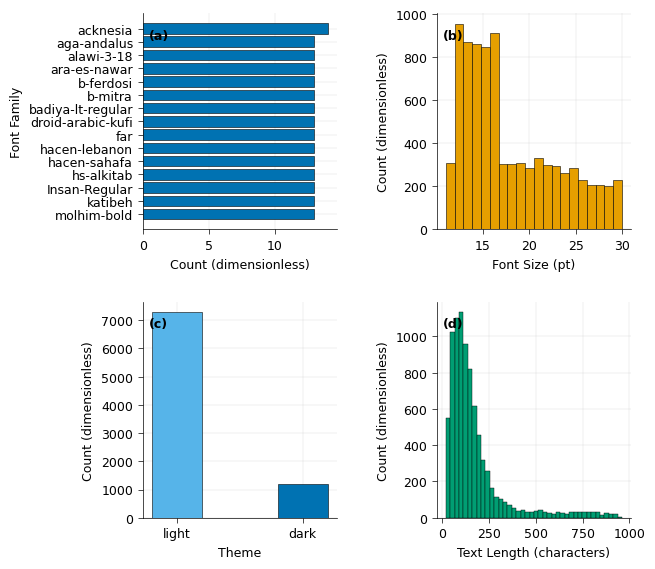

In [16]:
# Fig1: Dataset distribution properties. Vector PDF format.
fig, axes = plt.subplots(2, 2, figsize=(6.85, 6.0)) # Slightly increased height to allow text breathing room
tr = pd.read_csv(C.SPLIT_DIR / "train.csv")

# Panel (a): Top-15 Fonts
tf = tr["font"].value_counts().head(15)
axes[0, 0].barh(range(len(tf)), tf.values, color=COLORS['zeroshot'], edgecolor='black', linewidth=0.4, zorder=3)
axes[0, 0].set_yticks(range(len(tf)))
axes[0, 0].set_yticklabels(tf.index, fontsize=FONT_SIZE_BASE - 2) # Reduced font size slightly for long font names
axes[0, 0].invert_yaxis()
axes[0, 0].set_xlabel("Count (dimensionless)")
axes[0, 0].set_ylabel("Font Family")

# Panel (b): Font size histogram
axes[0, 1].hist(tr["font_size"], bins=20, color=COLORS['raw1x'], edgecolor='black', linewidth=0.4, zorder=3)
axes[0, 1].set_xlabel("Font Size (pt)")
axes[0, 1].set_ylabel("Count (dimensionless)")

# Panel (c): Theme Distribution
tc = tr["theme"].value_counts()
axes[1, 0].bar(tc.index, tc.values, color=[COLORS['rawrepeat'], COLORS['zeroshot']], edgecolor='black', linewidth=0.4, width=0.4, zorder=3)
axes[1, 0].set_xlabel("Theme")
axes[1, 0].set_ylabel("Count (dimensionless)")

# Panel (d): Text length distribution
axes[1, 1].hist(tr["text"].astype(str).str.len(), bins=40, color=COLORS['aug100k'], edgecolor='black', linewidth=0.3, zorder=3)
axes[1, 1].set_xlabel("Text Length (characters)")
axes[1, 1].set_ylabel("Count (dimensionless)")

# Apply global styles and sub-panel lettering anchors
for idx, ax in enumerate(axes.flat):
    apply_ijdar_style(ax)
    ax.text(0.03, 0.93, f"({chr(97 + idx)})", transform=ax.transAxes, fontsize=FONT_SIZE_BASE, fontweight='bold', va='top', zorder=5)

# Replace constrained_layout with explicit safety margins to completely isolate text boundaries
plt.tight_layout(pad=2.0, w_pad=3.2, h_pad=2.5)
plt.savefig(os.path.join(OUTPUT_DIR, "Fig1.pdf"), format="pdf")
plt.show()


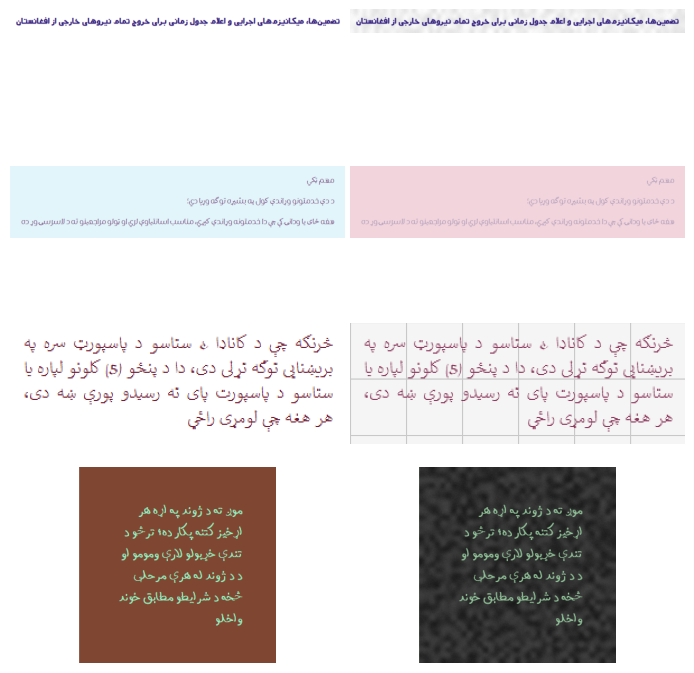

In [18]:
# Fig2: Production side-by-side raster comparison panels. TIFF at 600 DPI.
import random  
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from aug_lib import generate_background, replace_background, parse_annotation
from aug_quality import augment_image

# 1. Force close any lingering figure caches from prior cells
plt.close('all')

N_EXAMPLES = 4
train_df = pd.read_csv(C.SPLIT_DIR / "train.csv")
samples = train_df.sample(N_EXAMPLES, random_state=7)

fig, axes = plt.subplots(N_EXAMPLES, 2, figsize=(6.85, 7.5))

for i, (_, r) in enumerate(samples.iterrows()):
    img_path = str(C.RAW_IMG_DIR / r["file_name"])
    img = cv2.imread(img_path)
    
    if img is None:
        raise FileNotFoundError(f"Could not load image at path: {img_path}. Verify your path settings.")
        
    h, w = img.shape[:2]
    theme = r["theme"] if r["theme"] in ("light", "dark") else "light"
    box = [float(v) for v in parse_annotation(r["bbox"])]

    s = 1000 + i
    random.seed(s)
    np.random.seed(s)
    
    comp = replace_background(img, generate_background(w, h, theme), theme)
    
    # FIXED SYNTAX: Corrected the arguments signature to remove the duplicate comma
    out_img, _, _, _ = augment_image(img, comp, theme, [box], [0], s)

    # Cast arrays to standard unsigned 8-bit matrices to ensure visibility
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.uint8)
    
    if out_img.max() <= 1.0 and out_img.dtype != np.uint8:
        out_img_rgb = cv2.cvtColor((out_img * 255).astype(np.uint8), cv2.COLOR_BGR2RGB)
    else:
        out_img_rgb = cv2.cvtColor(out_img.astype(np.uint8), cv2.COLOR_BGR2RGB)

    # Bind the true image pixels directly onto clean axis surfaces
    axes[i, 0].imshow(img_rgb)
    axes[i, 1].imshow(out_img_rgb)
    
    for ax in (axes[i, 0], axes[i, 1]):
        ax.axis("off")  # Completely clears axis lines, labels, and frames
        for spine in ax.spines.values():
            spine.set_linewidth(0.4)

plt.tight_layout(pad=0.4)

# 2. Save vector-independent raster elements directly to production paths
plt.savefig(os.path.join(OUTPUT_DIR, "Fig2.tif"), format="tiff", dpi=600)
plt.savefig(os.path.join(OUTPUT_DIR, "Fig2.png"), format="png", dpi=600)
plt.show()

# 3. Clean environment state immediately
plt.close(fig)


## Figure: model comparison with confidence intervals

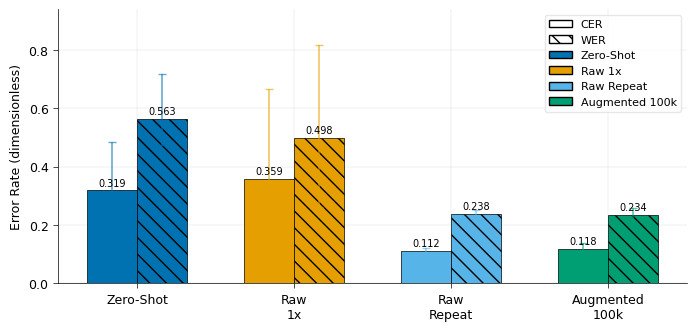

In [7]:
# Fig3: Error metrics with 95% bootstrap CIs. Vector PDF format.
t = table.reset_index(drop=True)
x = np.arange(len(t))
wd = 0.32

fig, ax = plt.subplots(figsize=(6.85, 3.2), constrained_layout=True)
apply_ijdar_style(ax)

labels_dict = {"zeroshot": "Zero-Shot", "raw1x": "Raw 1x", "rawrepeat": "Raw Repeat", "aug100k": "Augmented 100k"}

for offset_val, metric, lo_col, hi_col, hatch_pattern in [
    (-wd/2, "CER", "CER_lo", "CER_hi", ""), 
    (wd/2, "WER", "WER_lo", "WER_hi", "\\\\")
]:
    x_pos = x + offset_val
    bar_colors = [COLORS.get(k, "#0072B2") for k in t["tag"]]
    
    ax.bar(x_pos, t[metric], wd, hatch=hatch_pattern, color=bar_colors, edgecolor="black", linewidth=0.5, zorder=3)
    
    err_lower = (t[metric] - t[lo_col]).clip(lower=0)
    err_upper = (t[hi_col] - t[metric]).clip(lower=0)
    
    for xi, val, el, eu, col in zip(x_pos, t[metric], err_lower, err_upper, bar_colors):
        ax.errorbar(xi, val, yerr=[[el], [eu]], fmt='none', ecolor=col, elinewidth=1.2, capsize=3, capthick=1.0, alpha=0.6, zorder=4)
        ax.text(xi, val + 0.015, f"{val:.3f}", ha="center", fontsize=FONT_SIZE_BASE - 2, zorder=5)

ax.set_xticks(x)
ax.set_xticklabels([labels_dict.get(k, k).replace(" ", "\n") for k in t["tag"]], fontsize=FONT_SIZE_BASE)
ax.set_ylabel("Error Rate (dimensionless)")
ax.set_ylim(0, max(t["WER_hi"].max(), t["CER_hi"].max()) * 1.15)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#FFFFFF', edgecolor='black', hatch='', label='CER'),
    Patch(facecolor='#FFFFFF', edgecolor='black', hatch='\\\\', label='WER'),
    Patch(facecolor=COLORS['zeroshot'], edgecolor='black', label='Zero-Shot'),
    Patch(facecolor=COLORS['raw1x'], edgecolor='black', label='Raw 1x'),
    Patch(facecolor=COLORS['rawrepeat'], edgecolor='black', label='Raw Repeat'),
    Patch(facecolor=COLORS['aug100k'], edgecolor='black', label='Augmented 100k')
]
ax.legend(handles=legend_elements, loc="upper right", fontsize=FONT_SIZE_BASE - 1, frameon=True, edgecolor='#E2E2E2')

plt.savefig(os.path.join(OUTPUT_DIR, "Fig3.pdf"), format="pdf")
plt.show()


## Figure: training and validation loss (all three runs)

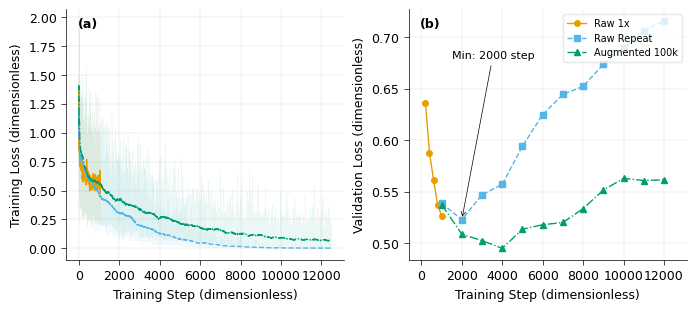

In [8]:
# Fig4: Training vs Validation line trajectories. Vector PDF format.
fig, ax = plt.subplots(1, 2, figsize=(6.85, 3.0), sharex=True, constrained_layout=True)
apply_ijdar_style(ax[0])
apply_ijdar_style(ax[1])

styles = {"zeroshot": (":", "v"), "raw1x": ("-", "o"), "rawrepeat": ("--", "s"), "aug100k": ("-.", "^")}
labels_dict = {"zeroshot": "Zero-Shot", "raw1x": "Raw 1x", "rawrepeat": "Raw Repeat", "aug100k": "Augmented 100k"}

min_val_step = None
min_val_loss = float('inf')

for m in ("raw1x", "rawrepeat", "aug100k"):
    p = C.RESULTS_DIR / f"loss_{m}.csv"
    if not p.exists(): continue
    d = pd.read_csv(p)
    tr = d.dropna(subset=["loss"])
    va = d.dropna(subset=["eval_loss"])
    
    w = max(5, len(tr) // 50)
    sm = tr["loss"].rolling(w, min_periods=1).mean()
    
    # Subplot (a): Training Curves
    ax[0].plot(tr["step"], sm, color=COLORS[m], linestyle=styles[m][0], linewidth=1.0, label=labels_dict[m], zorder=4)
    ax[0].plot(tr["step"], tr["loss"], color=COLORS[m], alpha=0.08, linewidth=0.4, zorder=3)
    
    # Subplot (b): Validation Curves
    if len(va):
        ax[1].plot(va["step"], va["eval_loss"], marker=styles[m][1], markersize=4, linestyle=styles[m][0], 
                   color=COLORS[m], linewidth=1.0, label=labels_dict[m], zorder=4)
        
        if m == "rawrepeat":
            min_idx = va["eval_loss"].idxmin()
            if pd.notna(min_idx):
                min_val_step = va.loc[min_idx, "step"]
                min_val_loss = va.loc[min_idx, "eval_loss"]

if min_val_step is not None:
    ax[1].annotate(f"Min: {int(min_val_step)} step",
                   xy=(min_val_step, min_val_loss),
                   xytext=(min_val_step - (min_val_step * 0.25), min_val_loss * 1.3),
                   fontsize=FONT_SIZE_BASE - 1,
                   arrowprops=dict(arrowstyle="->", color="black", linewidth=0.5))
    
ax[0].set_xlabel("Training Step (dimensionless)")
ax[0].set_ylabel("Training Loss (dimensionless)")
ax[1].set_xlabel("Training Step (dimensionless)")
ax[1].set_ylabel("Validation Loss (dimensionless)")

ax[0].text(0.04, 0.93, "(a)", transform=ax[0].transAxes, fontsize=FONT_SIZE_BASE, fontweight='bold')
ax[1].text(0.04, 0.93, "(b)", transform=ax[1].transAxes, fontsize=FONT_SIZE_BASE, fontweight='bold')
ax[1].legend(frameon=True, fontsize=FONT_SIZE_BASE - 2, loc="upper right", edgecolor='#E2E2E2')

plt.savefig(os.path.join(OUTPUT_DIR, "Fig4.pdf"), format="pdf")
plt.show()


C:\Users\shahi\AppData\Local\Temp\ipykernel_42252\583590841.py:23: UserWarning: Glyph 1741 (\N{ARABIC LETTER YEH WITH TAIL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(pad=0.4)
C:\Users\shahi\AppData\Local\Temp\ipykernel_42252\583590841.py:23: UserWarning: Matplotlib currently does not support Arabic natively.
  plt.tight_layout(pad=0.4)
C:\Users\shahi\AppData\Local\Temp\ipykernel_42252\583590841.py:24: UserWarning: Glyph 1741 (\N{ARABIC LETTER YEH WITH TAIL}) missing from font(s) DejaVu Sans.
  plt.savefig(os.path.join(OUTPUT_DIR, "Fig5.tif"), format="tiff", dpi=600)
C:\Users\shahi\AppData\Local\Temp\ipykernel_42252\583590841.py:24: UserWarning: Matplotlib currently does not support Arabic natively.
  plt.savefig(os.path.join(OUTPUT_DIR, "Fig5.tif"), format="tiff", dpi=600)
C:\Users\shahi\AppData\Local\Temp\ipykernel_42252\583590841.py:25: UserWarning: Glyph 1741 (\N{ARABIC LETTER YEH WITH TAIL}) missing from font(s) DejaVu Sans.
  plt.savefig(os.path.join(OUTPUT_DIR, "Fig5.

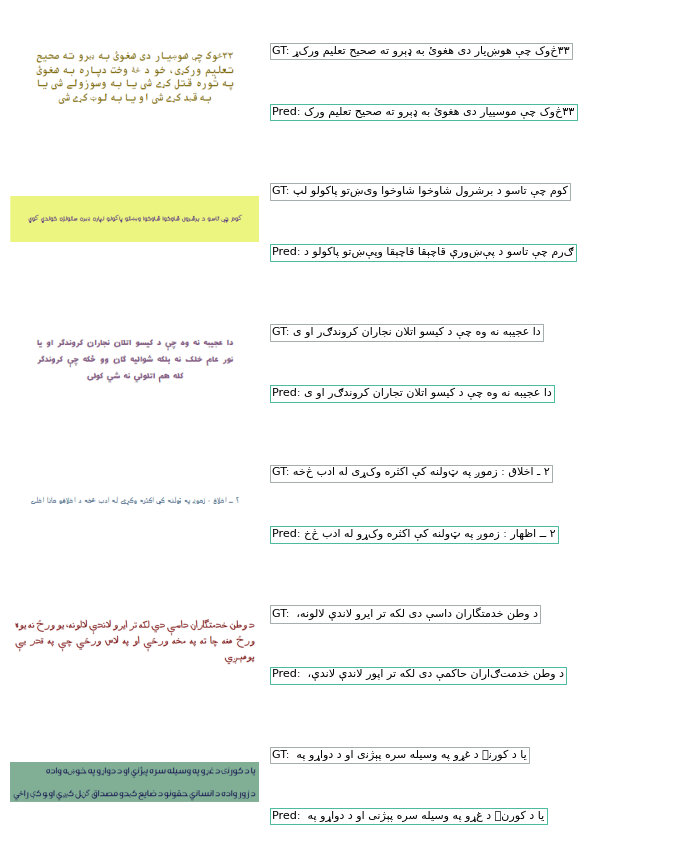

In [9]:
# Fig5: Grid of text predictions. TIFF at 600 DPI.
BEST = "aug100k" if "aug100k" in preds else list(preds)[-1]
d = preds[BEST].loc[common]
pick = d.sample(6, random_state=C.SEED)

fig, ax = plt.subplots(6, 2, figsize=(6.85, 8.5), gridspec_kw={"width_ratios": [1.2, 2.0]})

for i, (fn, r) in enumerate(pick.iterrows()):
    img = Image.open(C.RAW_IMG_DIR / fn)
    ax[i, 0].imshow(img)
    ax[i, 0].axis("off")
    ax[i, 1].axis("off")
    
    gt_str = "GT: " + rtl(r["ground_truth"][:50])
    pred_str = "Pred: " + rtl(r["prediction"][:50])
    
    # Text labels with white backgrounds to ensure a >4.5:1 contrast ratio
    ax[i, 1].text(0.02, 0.70, gt_str, ha="left", va="center", fontsize=FONT_SIZE_BASE - 1,
                  transform=ax[i, 1].transAxes, bbox=dict(boxstyle="square,pad=0.2", fc="#FFFFFF", ec="#7F8C8D", lw=0.5))
    ax[i, 1].text(0.02, 0.25, pred_str, ha="left", va="center", fontsize=FONT_SIZE_BASE - 1,
                  transform=ax[i, 1].transAxes, bbox=dict(boxstyle="square,pad=0.2", fc="#FFFFFF", ec="#009E73", lw=0.5))
    
plt.tight_layout(pad=0.4)
plt.savefig(os.path.join(OUTPUT_DIR, "Fig5.tif"), format="tiff", dpi=600)
plt.savefig(os.path.join(OUTPUT_DIR, "Fig5.png"), format="png", dpi=600)
plt.show()


## Figure: what the best model still gets wrong (top character substitutions)

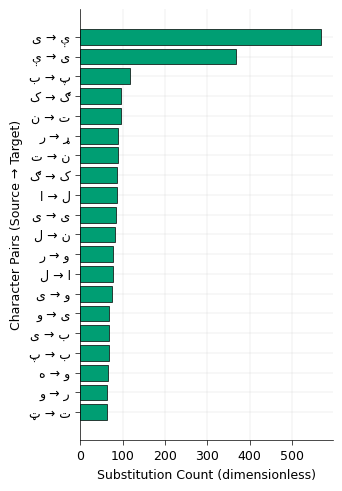

All IJDAR compliance steps complete. Figures saved inside: figures/


In [10]:
# Fig6: Top-20 character substitution frequencies. Single-column PDF format.
from rapidfuzz.distance import Levenshtein

subs = Counter()
for g, p in zip(d["ground_truth"], d["prediction"]):
    for op in Levenshtein.editops(g, p):
        if op.tag == "replace": 
            subs[(g[op.src_pos], p[op.dest_pos])] += 1
top = subs.most_common(20)

fig, ax = plt.subplots(figsize=(3.31, 4.8), constrained_layout=True)
apply_ijdar_style(ax)

counts = [n for _, n in top]
ax.barh(range(len(top)), counts, color=COLORS['aug100k'], edgecolor="black", linewidth=0.5, zorder=3)
ax.set_yticks(range(len(top)))

# Format character mapping labels using Bidirectional-safe Unicode characters
labels = [f"{rtl(a)} \u2192 {rtl(b)}" for (a, b), _ in top]
ax.set_yticklabels(labels, fontsize=FONT_SIZE_BASE)
ax.invert_yaxis()

ax.set_xlabel("Substitution Count (dimensionless)")
ax.set_ylabel("Character Pairs (Source \u2192 Target)")

plt.savefig(os.path.join(OUTPUT_DIR, "Fig6.pdf"), format="pdf")
plt.show()
print("All IJDAR compliance steps complete. Figures saved inside: figures/")
